# Online Shoppers Purchasing Intention Prediction

## Assignment 1 — Data Preparation & Leakage-Free Pipeline

**Course:** CS-13410 — Introduction to Machine Learning  
**Project:** Online Shoppers Purchasing Intention  
**Task:** Binary Classification  
**Target Variable:** Revenue

## 1. Problem Definition

The objective of this project is to predict whether an online shopping session will result in a purchase based on the visitor's browsing behavior and session characteristics.

The target variable is `Revenue`, which indicates whether a purchase was made during the session. This is a binary classification problem because the target has two possible outcomes: `True` (purchase) and `False` (no purchase).

The success of the model will be evaluated using appropriate classification metrics, with particular attention to the class imbalance present in the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (12330, 18)


## 2. Initial Dataset Understanding

The Online Shoppers Purchasing Intention dataset contains 12,330 online shopping sessions and 18 attributes. The objective of this project is to predict whether a browsing session results in a purchase.

The target variable is `Revenue`, which is a binary variable:
- `True`: the session resulted in a purchase.
- `False`: the session did not result in a purchase.

The dataset contains both numerical and categorical features. Initial inspection shows that there are no missing values. The target variable is imbalanced, with substantially more sessions resulting in no purchase than sessions resulting in a purchase.

Duplicate records were also checked during the initial data-quality analysis.

In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [5]:
df.shape

(12330, 18)

In [6]:
df.columns

Index(['Administrative', 'Administrative_Duration', 'Informational',
       'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
       'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend', 'Revenue'],
      dtype='object')

In [7]:
df["Revenue"].value_counts()

,count
Revenue,
False,10422
True,1908


In [8]:
df["Revenue"].value_counts(normalize=True) * 100

,proportion
Revenue,
False,84.525547
True,15.474453


In [9]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 125


## 3. Identifying Numerical and Categorical Features

Machine learning preprocessing depends on the type of each feature. Numerical features may require scaling, while categorical features need to be converted into numerical representations through encoding.

The dataset contains both numerical and categorical variables. The target variable, `Revenue`, is excluded from the input features because it is the variable we want to predict.

In [11]:
# Identify numerical features
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

Numerical Features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


In [12]:
# Identify categorical features
categorical_features = df.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

Categorical Features:
['Month', 'VisitorType', 'Weekend', 'Revenue']


In [13]:
# Remove the target variable from the feature lists
categorical_features.remove("Revenue")

print("Categorical Features after removing target:")
print(categorical_features)

Categorical Features after removing target:
['Month', 'VisitorType', 'Weekend']


In [14]:
print("Numerical Features:")
for feature in numerical_features:
    print("-", feature)

print("\nCategorical Features:")
for feature in categorical_features:
    print("-", feature)

Numerical Features:
- Administrative
- Administrative_Duration
- Informational
- Informational_Duration
- ProductRelated
- ProductRelated_Duration
- BounceRates
- ExitRates
- PageValues
- SpecialDay
- OperatingSystems
- Browser
- Region
- TrafficType

Categorical Features:
- Month
- VisitorType
- Weekend


In [15]:
print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))
print("Total input features:", len(numerical_features) + len(categorical_features))

Number of numerical features: 14
Number of categorical features: 3
Total input features: 17


In [16]:
feature_summary = pd.DataFrame({
    "Feature Type": ["Numerical", "Categorical", "Target"],
    "Number of Features": [
        len(numerical_features),
        len(categorical_features),
        1
    ]
})

feature_summary

,Feature Type,Number of Features
0,Numerical,14
1,Categorical,3
2,Target,1


### Interpretation

The dataset contains 14 numerical input features and 3 categorical input features. The target variable `Revenue` is treated separately because it represents the outcome that the model will predict.

The numerical features will later be considered for imputation and scaling, while the categorical features will be processed using categorical encoding. A `ColumnTransformer` will be used to apply the appropriate preprocessing to each feature type within a leakage-free machine learning pipeline.

## 4. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distribution of the target variable and examine relationships between selected features and the purchase outcome.

### 4.1 Target Variable Distribution

The target variable `Revenue` is analyzed to evaluate the balance between sessions that resulted in a purchase (`True`) and those that did not (`False`).

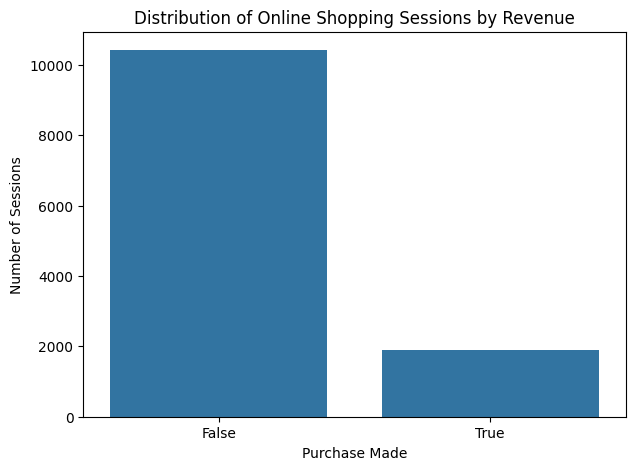

In [17]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Revenue")

plt.title("Distribution of Online Shopping Sessions by Revenue")
plt.xlabel("Purchase Made")
plt.ylabel("Number of Sessions")

plt.show()

In [18]:
revenue_percent = df["Revenue"].value_counts(normalize=True) * 100

print("Revenue distribution (%):")
print(revenue_percent)

Revenue distribution (%):
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


### Interpretation

The target variable `Revenue` is imbalanced. Most online shopping sessions do not result in a purchase, while a smaller proportion of sessions result in a purchase. This class imbalance should be considered when evaluating classification models in later stages of the project.

### 4.2 Product-Related Duration and Purchase Outcome

The `ProductRelated_Duration` feature represents the amount of time a visitor spends on product-related pages during a shopping session. Its distribution is examined across the two purchase outcomes.

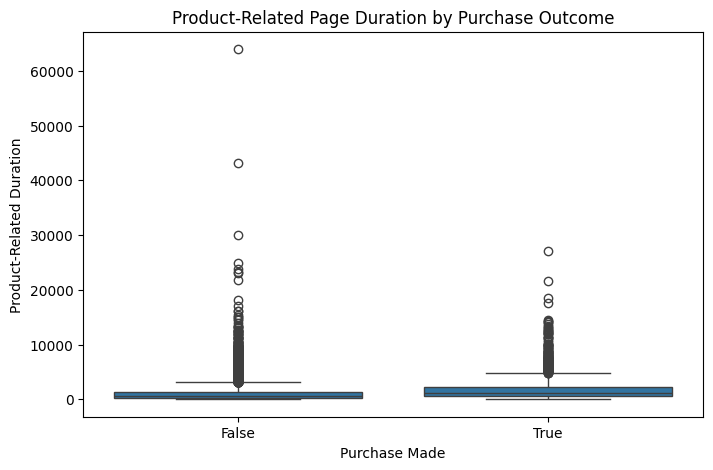

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Revenue", y="ProductRelated_Duration")

plt.title("Product-Related Page Duration by Purchase Outcome")
plt.xlabel("Purchase Made")
plt.ylabel("Product-Related Duration")

plt.show()

### Interpretation

The boxplot shows the distribution of product-related page duration for sessions with and without a purchase. The distributions show variation in browsing duration and contain some extreme observations. This indicates that `ProductRelated_Duration` may contain outliers, which should be considered during the data-quality and preprocessing stages.

### 4.3 Page Value and Purchase Outcome

The `PageValues` feature represents the average value of pages viewed by the visitor before completing a transaction. Its distribution is examined across sessions with and without a purchase to explore its relationship with the target variable `Revenue`.

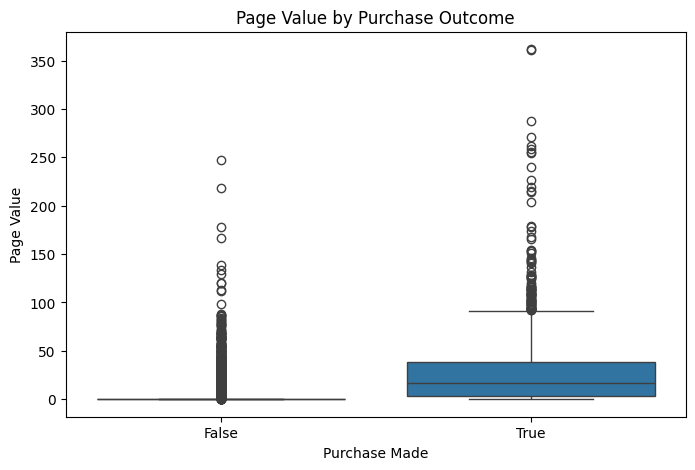

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Revenue", y="PageValues")

plt.title("Page Value by Purchase Outcome")
plt.xlabel("Purchase Made")
plt.ylabel("Page Value")

plt.show()

### Interpretation

The boxplot shows a difference in the distribution of `PageValues` between sessions that resulted in a purchase and those that did not. Sessions resulting in a purchase generally show higher page-value observations, while non-purchasing sessions contain many values close to zero. The presence of extreme observations also indicates that this feature should be considered when investigating outliers.

## 5. Data Quality Analysis

Before applying preprocessing techniques and building the machine learning pipeline, the dataset is examined for common data-quality issues. These include missing values, duplicate records, potential outliers, and class imbalance.

### 5.1 Missing Values

Missing values are checked to determine whether any features require imputation before model training. Identifying missing values at this stage helps ensure that the preprocessing pipeline can handle the data appropriately.

In [21]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [22]:
total_missing = df.isnull().sum().sum()

print("Total missing values:", total_missing)

Total missing values: 0


### Interpretation

The dataset contains no missing values, as the total number of missing values across all columns is zero. Therefore, no missing-value imputation is required for the current dataset. However, the preprocessing pipeline can still include appropriate imputation steps where necessary to make the workflow robust and suitable for machine learning.

### 5.2 Duplicate Records

Duplicate records are checked to determine whether identical shopping sessions appear more than once in the dataset. Removing unintended duplicates can help prevent repeated observations from affecting the model's learning process.

In [23]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 125


In [24]:
duplicate_percentage = (duplicate_count / len(df)) * 100

print("Percentage of duplicate records:", duplicate_percentage, "%")

Percentage of duplicate records: 1.013787510137875 %


### Interpretation

The dataset contains 125 duplicate records, representing approximately 1.01% of the total observations. These duplicate records may cause certain sessions to be represented more than once and could affect model training if left untreated. Therefore, the duplicate records will be removed before the data is used for model training.

### 5.3 Outlier Analysis

Potential outliers are investigated in the numerical features because extreme observations were visible in the EDA boxplots. The Interquartile Range (IQR) method is used to identify observations that fall below the lower bound or above the upper bound.

In [25]:
outlier_summary = {}

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    outlier_summary[col] = len(outliers)

print("Number of potential outliers in each numerical feature:")

for feature, count in outlier_summary.items():
    print(f"{feature}: {count}")

Number of potential outliers in each numerical feature:
Administrative: 404
Administrative_Duration: 1172
Informational: 2631
Informational_Duration: 2405
ProductRelated: 987
ProductRelated_Duration: 961
BounceRates: 1551
ExitRates: 1099
PageValues: 2730
SpecialDay: 1251
OperatingSystems: 111
Browser: 4369
Region: 511
TrafficType: 2101


In [26]:
outlier_table = pd.DataFrame(
    list(outlier_summary.items()),
    columns=["Feature", "Potential Outliers"]
)

outlier_table

,Feature,Potential Outliers
0,Administrative,404
1,Administrative_Duration,1172
2,Informational,2631
3,Informational_Duration,2405
4,ProductRelated,987
5,ProductRelated_Duration,961
6,BounceRates,1551
7,ExitRates,1099
8,PageValues,2730
9,SpecialDay,1251


### Interpretation

The IQR analysis identified potential outliers across all numerical features. The number of flagged observations varies considerably between features, with some variables containing a relatively large number of observations outside the IQR boundaries. These observations are not automatically treated as errors because extreme values may represent legitimate differences in visitor browsing behavior.

Therefore, the identified observations will not be removed solely on the basis of the IQR analysis. Instead, appropriate preprocessing techniques, including feature scaling where applicable, will be applied within the machine learning pipeline. This approach preserves potentially meaningful observations while reducing the influence of differences in feature scale.

### 5.4 Class Imbalance

Class imbalance is examined because the target variable `Revenue` contains two classes with substantially different numbers of observations. Understanding the class distribution is important because accuracy alone may not adequately represent model performance when one class is much more common than the other.

In [27]:
class_counts = df["Revenue"].value_counts()

print("Class distribution:")
print(class_counts)

Class distribution:
Revenue
False    10422
True      1908
Name: count, dtype: int64


In [28]:
class_percentages = df["Revenue"].value_counts(normalize=True) * 100

print("Class distribution (%):")
print(class_percentages)

Class distribution (%):
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


In [29]:
class_summary = pd.DataFrame({
    "Class": class_counts.index,
    "Count": class_counts.values,
    "Percentage": class_percentages.values
})

class_summary

,Class,Count,Percentage
0,False,10422,84.525547
1,True,1908,15.474453


### Interpretation

The class distribution shows a clear imbalance between the two `Revenue` outcomes. Sessions that do not result in a purchase represent the majority of observations, while purchasing sessions represent a substantially smaller proportion of the dataset. Because of this imbalance, model evaluation should use appropriate classification metrics in addition to accuracy, such as precision, recall, F1-score, and the confusion matrix.

## 6. Train-Test Split

The dataset is divided into training and testing subsets before applying preprocessing techniques. The training data will be used to learn preprocessing parameters and train the machine learning models, while the testing data will remain separate for evaluating model performance.

Stratified splitting is used to preserve the proportion of the two `Revenue` classes in both subsets. This is particularly important because the target variable is imbalanced.

In [30]:
# Separate input features and target variable
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (12330, 17)
Target shape: (12330,)


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (9864, 17)
Testing feature shape: (2466, 17)
Training target shape: (9864,)
Testing target shape: (2466,)


In [32]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training class distribution:
Revenue
False    84.529603
True     15.470397
Name: proportion, dtype: float64

Testing class distribution:
Revenue
False    84.509327
True     15.490673
Name: proportion, dtype: float64


### Interpretation

The dataset was divided into training and testing sets using an 80/20 split. Stratification was applied using the `Revenue` target variable to maintain a similar class distribution in both subsets. The training set will be used for learning preprocessing parameters and training models, while the testing set will remain unseen until model evaluation.

## 7. Leakage-Free Preprocessing Pipeline

A preprocessing pipeline is constructed to ensure that all preprocessing operations are performed consistently and without data leakage. Numerical and categorical features require different preprocessing strategies, so a `ColumnTransformer` is used to apply the appropriate transformations to each feature type.

The preprocessing steps will be fitted using only the training data. The same fitted transformations will then be applied to the testing data without allowing information from the test set to influence the learned preprocessing parameters.

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

### 7.1 Numerical Feature Preprocessing

Numerical features are processed using two steps. Missing numerical values are handled using median imputation, and the resulting values are standardized using `StandardScaler`. Although the current dataset contains no missing values, including imputation makes the pipeline more robust.

In [34]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

### 7.2 Categorical Feature Preprocessing

Categorical features are processed using imputation followed by one-hot encoding. The most frequent category is used to fill any missing categorical values, while `OneHotEncoder` converts categorical values into numerical features suitable for machine learning algorithms.

In [35]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

### 7.3 Combining Feature Transformations

A `ColumnTransformer` is used to apply the numerical and categorical preprocessing pipelines to their respective columns. This allows different preprocessing operations to be performed within a single unified transformation.

In [36]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

### 7.4 Complete Machine Learning Pipeline

The preprocessing component is combined with a Logistic Regression classifier to create a complete machine learning pipeline. The pipeline ensures that preprocessing and model training are treated as a single workflow. When the pipeline is fitted, preprocessing parameters are learned only from the training data.

In [37]:
from sklearn.linear_model import LogisticRegression

In [38]:
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

### 7.5 Training the Pipeline

The complete pipeline is fitted using only the training data. During this process, the preprocessing transformations learn their required parameters from `X_train`, and the Logistic Regression classifier is trained using the transformed training features.

In [39]:
model_pipeline.fit(X_train, y_train)

print("Pipeline training completed successfully.")

Pipeline training completed successfully.


### 7.6 Test Set Prediction

After training, the fitted pipeline is used to generate predictions for the unseen testing data. The testing data is transformed using the preprocessing parameters learned from the training set.

In [40]:
y_pred = model_pipeline.predict(X_test)

print("Predictions generated successfully.")
print("Number of predictions:", len(y_pred))

Predictions generated successfully.
Number of predictions: 2466


## 8. Verifying the Pipeline and Checking for Data Leakage

In [41]:
print("Pipeline structure:")
print(model_pipeline)

Pipeline structure:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Administrative',
                                                   'Administrative_Duration',
                                                   'Informational',
                                                   'Informational_Duration',
                                                   'ProductRelated',
                                                   'ProductRelated_Duration',
                                                   'BounceRates', 'ExitRates',
                           

In [42]:
# Check the fitted numerical scaler
scaler = model_pipeline.named_steps["preprocessor"].named_transformers_["num"].named_steps["scaler"]

print("Scaler mean learned from training data:")
print(scaler.mean_)

print("\nScaler scale learned from training data:")
print(scaler.scale_)

Scaler mean learned from training data:
[2.31761963e+00 8.12410594e+01 5.04663423e-01 3.45902517e+01
 3.14527575e+01 1.18654601e+03 2.23955788e-02 4.33132784e-02
 5.94456179e+00 6.26926196e-02 2.12753447e+00 2.36678832e+00
 3.15277778e+00 4.07116788e+00]

Scaler scale learned from training data:
[3.31897604e+00 1.79601316e+02 1.27510418e+00 1.41421803e+02
 4.36132290e+01 1.90915551e+03 4.88065002e-02 4.88989715e-02
 1.85612280e+01 2.01260949e-01 9.18051467e-01 1.73272261e+00
 2.39581710e+00 4.01502703e+00]


In [43]:
# Check that the scaler parameters are based on the training set

train_means = X_train[numerical_features].mean().values
train_stds = X_train[numerical_features].std().values

print("Training means:")
print(train_means)

print("\nScaler learned means:")
print(scaler.mean_)

Training means:
[2.31761963e+00 8.12410594e+01 5.04663423e-01 3.45902517e+01
 3.14527575e+01 1.18654601e+03 2.23955788e-02 4.33132784e-02
 5.94456179e+00 6.26926196e-02 2.12753447e+00 2.36678832e+00
 3.15277778e+00 4.07116788e+00]

Scaler learned means:
[2.31761963e+00 8.12410594e+01 5.04663423e-01 3.45902517e+01
 3.14527575e+01 1.18654601e+03 2.23955788e-02 4.33132784e-02
 5.94456179e+00 6.26926196e-02 2.12753447e+00 2.36678832e+00
 3.15277778e+00 4.07116788e+00]


### 8.1 Verification of Data Leakage Prevention

The fitted `StandardScaler` parameters were compared with the corresponding statistics calculated directly from the training data. The learned means matched the training-set means, confirming that the scaler was fitted using the training data. The test data was not used when learning the preprocessing parameters. Therefore, the preprocessing pipeline follows a leakage-free approach in which preprocessing is fitted on the training set and subsequently applied to the unseen test set.

In [44]:
# Verify that predictions were generated from the fitted pipeline

print("Test set size:", len(X_test))
print("Number of predictions:", len(y_pred))

if len(X_test) == len(y_pred):
    print("Pipeline verification successful: all test observations received a prediction.")
else:
    print("Error: prediction count does not match test set size.")

Test set size: 2466
Number of predictions: 2466
Pipeline verification successful: all test observations received a prediction.


### 8.2 Problem Framing and Success Metric

This project is a binary classification problem in which the model predicts whether an online shopping session will result in a purchase. The target variable is `Revenue`, where `True` represents a purchase and `False` represents no purchase.

Because the target variable is imbalanced, accuracy alone may not provide a reliable measure of model performance. Therefore, model performance will be evaluated using **precision, recall, F1-score, and the confusion matrix**, with particular attention to the F1-score and recall for the purchasing class. These metrics provide a better understanding of how effectively the model identifies sessions that result in a purchase.

### 8.3 Feature Construction and Selection

The dataset contains a combination of numerical and categorical features that describe visitor browsing behavior and session characteristics. No additional derived features were constructed at this stage because the existing variables already provide relevant information for predicting the `Revenue` target.

The target variable `Revenue` was explicitly separated from the input features before model training to prevent target leakage. All remaining 17 variables were retained as predictors for the initial Logistic Regression model. Feature selection may be considered in later stages based on model performance and feature importance or coefficients.

### 8.4 Data Quality Treatment Decisions

The dataset contains no missing values, so no actual missing-value replacement was required. Median imputation for numerical variables and most-frequent imputation for categorical variables were nevertheless included in the preprocessing pipeline to make the workflow robust to potential missing values.

Potential outliers were identified using the IQR method. They were not automatically removed because extreme browsing behavior may represent legitimate visitor sessions rather than erroneous observations. Numerical standardization was therefore used within the pipeline instead of removing observations solely based on IQR thresholds.

The target variable is imbalanced, with purchasing sessions representing a smaller proportion of the observations. The original class distribution is retained for the initial model, while appropriate evaluation metrics such as precision, recall, F1-score, and the confusion matrix will be used to assess performance. Class-balancing techniques can be considered in later model-development stages if required.